# TCG Liquidity Risk — a step-by-step walkthrough

This notebook builds a liquidity-risk model for a portfolio of trading cards from scratch.
It is self-contained: every function is defined here, and it runs **offline** on the synthetic
sample dataset in `data/sample/` (generated by `scripts/make_sample_data.py`). No data is downloaded.

Every step has a **Concept** cell (what it is, the formula, why it is used) followed by the code.
The main example is **Card A**, a synthetic ~$2,100 single that sells about once every four days.
All numbers come from made-up data; the point is the method, not the prices.

**Requirements:** Python ≥ 3.10 and `pip install numpy "pandas>=2.2" scipy matplotlib`.
Run it from the `notebooks/` folder (or change `DATA` in step 1).


## The problem in one paragraph

A portfolio of cards has a **mark-to-market** value: quantity × the marketplace *market price*
(the average of recent sales). But that is not cash. TCGplayer is an **ask-only** market:
sellers post listings and wait; there is no standing bid to sell into. To turn a card into cash
you must price your listing so that buyers reach it before your deadline. So the real question is:

> *If I must sell **q** cards within **h** days, how much cash do I actually receive — and how sure am I?*

The gap between market value and that cash is **liquidity risk**. On top of it sits ordinary
**price risk**: while you wait, the market price itself can fall.

### Thesis

| Question | Answer |
|---|---|
| What is the mechanism? | In an ask-only market, a seller who must sell fast has to price below every competing listing that would otherwise be bought first, or sell to a shop at a deep discount. |
| Who is on the other side? | Patient sellers (paid by waiting) and shops/buylists (paid for providing immediacy). |
| What data confirms it? | Many listings relative to sales per day; shop buy prices well below market; haircuts that shrink as the allowed horizon grows. |
| What would invalidate it? | A deep, standing bid side (a real market maker), which would turn the price–time trade-off into a narrow spread. |

### Model map

| Layer | Concept | Step |
|---|---|---|
| Data | Weekly sales history + a snapshot of listings (local files) | 1, 3 |
| Demand | Overdispersed count model (Negative Binomial) | 2 |
| Selling | Ask ladder with price priority; fees; shop bid as the outside option | 3–6 |
| Price risk | VaR with Cornish–Fisher correction | 7 |
| Exogenous liquidity | Bangia et al. (1999) LVaR, Amihud | 8 |
| Portfolio | Diversified VaR, combined loss, stress tests | 9 |
| Sensitivity | Which assumption matters most | 10 |

## Step 0 · Setup
Imports and a clean plot style.

In [1]:
import json, math
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.grid": False,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
BLUE, RED, GREEN, GRAY, DARK = "#1f6fbf", "#c0392b", "#2e8b57", "#8a8a8a", "#222222"
pd.set_option("display.width", 140)

## Step 1 · Data

**Concept.** The model needs two inputs per item:

* **weekly history** — 52 weekly rows with the market price, units sold, number of transactions, and the
  lowest/highest sale price of the week;
* **listings** — a snapshot of every ask currently posted (price, shipping, quantity).

One year of weekly rows feeds both halves of the model: units sold → demand (step 2);
prices → returns and a spread proxy (steps 7–8).

Here they come from CSV files in `data/sample/` (synthetic). To use your own data, put files with the same
columns in a folder of your own and point `DATA` at it: `weekly/<id>.csv` and `listings/<id>.csv`.


In [2]:
from pathlib import Path

DATA = Path("../data/sample")          # change to your own dataset folder


def load_weekly(item_id):
    """Weekly history plus the derived columns the model uses: ret, spread, dvol."""
    df = pd.read_csv(DATA / "weekly" / f"{item_id}.csv")
    df["date"] = pd.to_datetime(df["date"])
    df = df.sort_values("date").reset_index(drop=True)
    for c in ("market", "qty", "txn", "low", "high"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    df.loc[df["market"] <= 0, "market"] = np.nan
    df["market"] = df["market"].ffill()
    df["ret"] = np.log(df["market"]).diff()                       # weekly log return
    ok = (df["txn"] >= 2) & (df["market"] > 0)
    df["spread"] = np.where(ok, (df["high"] - df["low"]) / df["market"], np.nan)   # weekly sale-price range
    df["dvol"] = df["qty"].fillna(0) * df["market"]               # dollar volume
    return df


def load_listings(item_id):
    """Every listed ask: price, shipping, quantity."""
    return pd.read_csv(DATA / "listings" / f"{item_id}.csv").to_dict("records")


In [3]:
ITEM, QTY = "card_a", 1          # Card A · chase single (synthetic)

portfolio = json.loads((DATA / "portfolio.json").read_text(encoding="utf-8"))
pd.DataFrame(portfolio["positions"])


,id,name,qty,reprint_risk
0,card_a,Card A · chase single,1,False
1,card_b,Card B · alt-art single,1,False
2,card_c,Card C · new-set chase card,2,True
3,card_d,Card D · mid-value single,3,True
4,box_e,Box E · sealed booster box,1,False
5,box_f,Box F · premium collection,2,False
6,box_g,Box G · exclusive box,4,False


### The model's code

The next two cells define every model function and setting used below (horizons, confidence levels, the 60% shop bid,
the stress scenarios). It is the model's code exactly as written; the following steps explain each piece and recompute it by hand.

`weekly_frame` turns the chosen SKU into a tidy table, oldest week first, with three derived columns:

| Column | Formula | Used for |
|---|---|---|
| `ret` | $\ln(P_t / P_{t-1})$ | price risk (step 7) |
| `spread` | $(\text{high} - \text{low}) / \text{market}$, weeks with ≥ 2 transactions | Bangia spread proxy (step 8) |
| `dvol` | units sold × market price | Amihud (step 8) |

In [4]:
import math
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
from scipy import stats

FEE_PCT = 0.1325      # marketplace commission 10.75% + payment processing 2.5%
FEE_FIXED = 0.3    # per order
TICK = 0.01         # undercut increment

def ship_cost(landed_price: float) -> float:
    """Seller's own shipping cost by value tier (envelope → tracked → insured)."""
    if landed_price < 20:
        return 0.75
    if landed_price < 50:
        return 1.50
    if landed_price < 250:
        return 5.50
    return 12.00

def net_proceeds(landed_price: float) -> float:
    """Cash kept per unit sold at a landed price (seller charges shipping = cost)."""
    return max(0.0, landed_price * (1 - FEE_PCT) - FEE_FIXED - ship_cost(landed_price))

@dataclass
class Demand:
    lam_day: float      # units / day (recent window)
    phi: float          # dispersion index of weekly counts (≥ 1)

    def quantile(self, h_days: float, alpha: float) -> int:
        """α-quantile of units demanded in h days (α small = stressed/low demand)."""
        m = self.lam_day * h_days
        if m <= 0:
            return 0
        if self.phi <= 1.0 + 1e-9:
            return int(stats.poisson.ppf(alpha, m))
        n = m / (self.phi - 1.0)          # NegBin(n, p): mean m, var φm
        return int(stats.nbinom.ppf(alpha, n, 1.0 / self.phi))

def fit_demand(weekly_qty: list[float], recent_weeks: int = 13) -> Demand:
    q = np.asarray([x for x in weekly_qty if x is not None and not math.isnan(x)], float)
    if q.size == 0:
        return Demand(0.0, 1.0)
    recent = q[-recent_weeks:]
    mean_all = q.mean()
    phi = float(q.var(ddof=1) / mean_all) if q.size > 2 and mean_all > 0 else 1.0
    return Demand(lam_day=float(recent.mean() / 7.0), phi=max(1.0, phi))

@dataclass
class Level:
    landed: float       # price + shipping
    qty: int

def ladder_from_listings(rows: list[dict]) -> list[Level]:
    """Aggregate raw listings into price levels sorted by landed price."""
    agg: dict[float, int] = {}
    for r in rows:
        p = round(float(r["price"]) + float(r.get("shipping", 0.0)), 2)
        agg[p] = agg.get(p, 0) + int(r["qty"])
    return [Level(p, q) for p, q in sorted(agg.items())]

def clean_ladder(ladder: list[Level], market: float, floor: float = 0.60) -> list[Level]:
    """Drop asks below floor·market.  They are stale/mislabelled listings (a real
    ask at 10% of market would have been bought) and would otherwise force the
    model to 'undercut' a price nobody can actually compete with."""
    return [l for l in ladder if l.landed >= floor * market]

def scale_ladder(ladder: list[Level], price_mult: float = 1.0, depth_mult: float = 1.0) -> list[Level]:
    return [Level(round(l.landed * price_mult, 2), max(1, int(round(l.qty * depth_mult))))
            for l in ladder]

@dataclass
class Liquidation:
    h_days: float
    alpha: float
    q: int
    demand: int              # D_h,α
    price: float             # landed price p* for the units sold on-market
    sold_market: int
    dumped: int
    proceeds: float          # total cash
    haircut: float           # 1 − proceeds / (q·market)

def liquidate(ladder: list[Level], market: float, q: int, demand: Demand, h_days: float,
              alpha: float = 0.05, dump_frac: float = 0.60) -> Liquidation:
    """Best (highest) price that clears q units within h days at confidence 1−α."""
    D = demand.quantile(h_days, alpha)
    cap = market                      # never assume a sale above market
    if D >= q:
        room = D - q                  # units we may tolerate ahead of us
        price = cap
        ahead = 0
        for lvl in ladder:            # undercut the first level that would overflow room
            if ahead + lvl.qty > room:
                price = min(cap, lvl.landed - TICK)
                break
            ahead += lvl.qty
        sold, dumped = q, 0
    else:                             # can't clear q: jump the whole queue, dump the rest
        best = ladder[0].landed - TICK if ladder else cap
        price = min(cap, best)
        sold, dumped = D, q - D
    price = max(price, 0.0)
    bid = dump_frac * market          # outside option: sell to a shop instead
    if net_proceeds(price) < bid:     # undercutting that deep is worse than the shop bid
        sold, dumped = 0, q
    proceeds = sold * net_proceeds(price) + dumped * bid
    hc = 1.0 - proceeds / (q * market) if q > 0 and market > 0 else float("nan")
    return Liquidation(h_days, alpha, q, D, round(price, 2), sold, dumped, proceeds, hc)

def days_to_liquidate(ladder, market, q, demand, max_haircut: float, alpha: float = 0.05,
                      max_days: int = 365, dump_frac: float = 0.60) -> int | None:
    """Shortest horizon (days) whose stressed haircut ≤ max_haircut, else None."""
    for h in list(range(1, 31)) + list(range(35, max_days + 1, 5)):
        if liquidate(ladder, market, q, demand, h, alpha, dump_frac).haircut <= max_haircut:
            return h
    return None

_ZGRID = np.linspace(-4.0, 4.0, 161)

def cornish_fisher_var(r: np.ndarray, conf: float, horizon: int = 1) -> float:
    """Loss quantile over ``horizon`` periods (positive = loss, log-return units).

    Drift scales with H, volatility with √H.  Positive drift is not credited
    (Bangia et al. set E[r] = 0; crediting a hype-driven uptrend would shrink the
    risk number exactly when it is least trustworthy), negative drift is kept.
    The skew/kurtosis adjustment uses the per-period moments — under iid they
    would shrink as s/√H and k/H, so keeping them is the conservative choice.

    Cornish–Fisher is only valid while z ↦ z_cf is monotone.  Extreme moments
    (thinly traded cards: mostly zero weeks plus one jump) break that and can
    even flip the sign of the loss, so outside the valid domain the standardized
    empirical quantile is used instead, never less severe than the normal z.
    The loss is floored at 0.
    """
    r = r[~np.isnan(r)]
    if r.size < 8:
        return float("nan")
    z = stats.norm.ppf(1 - conf)
    s, k = stats.skew(r), stats.kurtosis(r)   # excess kurtosis
    sd = float(r.std(ddof=1))
    if cf_valid(s, k):
        zq = cf_z(z, s, k)
    else:
        z_emp = (float(np.quantile(r, 1 - conf)) - float(r.mean())) / sd if sd > 0 else z
        zq = min(z, z_emp)
    drift = min(float(r.mean()), 0.0) * horizon
    return max(0.0, float(-(drift + zq * sd * math.sqrt(horizon))))

def cf_z(z, s: float, k: float):
    """Cornish–Fisher adjusted standard-normal quantile."""
    return z + (z**2 - 1) * s / 6 + (z**3 - 3 * z) * k / 24 - (2 * z**3 - 5 * z) * s**2 / 36

def cf_valid(s: float, k: float) -> bool:
    """True if the Cornish–Fisher map is strictly increasing on z ∈ [−4, 4]."""
    return bool(np.all(np.diff(cf_z(_ZGRID, s, k)) > 0))

@dataclass
class Bangia:
    price_var: float          # % loss, horizon H weeks
    spread_mean: float
    spread_sd: float
    a: float                  # spread scaling factor actually used
    liq_addon: float
    lvar: float

def spread_scale(s: np.ndarray, conf: float) -> float:
    """Bangia's scaling factor a: μ_S + a·σ_S should cover the conf-tail of the
    spread.  Spreads are far from normal (the paper finds a ≈ 2.0–4.5), so a is
    read off the empirical quantile, floored at the normal z for thin samples."""
    z = float(stats.norm.ppf(conf))
    sd = float(s.std(ddof=1))
    if s.size < 20 or sd <= 0:
        return z
    return max(z, (float(np.quantile(s, conf)) - float(s.mean())) / sd)

def bangia_lvar(weekly_ret: np.ndarray, weekly_spread: np.ndarray, conf: float = 0.95,
                horizon_weeks: int = 4) -> Bangia:
    """Bangia et al. (1999):  LVaR/P = 1 − e^{r_α,H} + ½(μ_S + a·σ_S).

    The spread term is a one-off exit cost, so it does not scale with H.
    Additive form assumes the worst price and the worst spread coincide.
    """
    v = cornish_fisher_var(weekly_ret, conf, horizon_weeks)
    pv = 1 - math.exp(-v) if not math.isnan(v) else float("nan")
    s = weekly_spread[~np.isnan(weekly_spread)]
    if s.size > 2:
        mu, sd = float(s.mean()), float(s.std(ddof=1))
        a = spread_scale(s, conf)
    else:
        mu = sd = a = float("nan")
    add = 0.5 * (mu + a * sd)
    return Bangia(pv, mu, sd, a, add, pv + add)

def amihud(weekly_ret: np.ndarray, weekly_dollar_vol: np.ndarray) -> float:
    """Mean |r| per $1k traded (higher = each dollar moves price more)."""
    m = (weekly_dollar_vol > 0) & ~np.isnan(weekly_ret)
    if m.sum() < 4:
        return float("nan")
    return float(np.mean(np.abs(weekly_ret[m]) / weekly_dollar_vol[m]) * 1e3)

@dataclass
class PositionRisk:
    name: str
    qty: int
    market: float
    value: float
    lam_day: float
    phi: float
    book_depth: int                      # units listed (NM, English)
    days_of_supply: float                # book_depth / λ
    best_ask: float
    liq: dict = field(default_factory=dict)          # {(h, α): Liquidation}
    days_to_liq: int | None = None        # stressed haircut ≤ MAX_HAIRCUT
    bangia: Bangia | None = None
    amihud: float = float("nan")
    combined_30d: float = float("nan")   # 1 − (1−VaR_30d)(1−haircut_30d,5%)
    dump_frac: float = 0.60              # shop / buylist bid used for this position
    bid_source: str = "assumed"          # assumed | calibrated <bucket> | position
    game: str = "Pokémon"
    trade_weeks: int = 0                 # weeks with ≥ 1 sale (of 52); < MIN_TRADE_WEEKS → VaR unreliable


In [5]:
HORIZONS = (1, 7, 30, 90)            # days
ALPHAS = (0.5, 0.05)           # 0.50 = normal demand (median), 0.05 = quiet market (5th percentile)
MAX_HAIRCUT = 0.2            # 'liquid' = can exit at ≤ 20% haircut
DUMP_FRAC = 0.6              # outside option: shop / buylist bid as a fraction of market
MIN_TRADE_WEEKS = 13          # fewer weeks with a sale → price VaR unreliable
SCENARIOS = {
    "demand_crunch": {
        "lam": 0.4,
        "price": 0.75,
        "depth": 1.5,
        "only_flagged": False
    },
    "reprint": {
        "lam": 0.7,
        "price": 0.65,
        "depth": 3.0,
        "only_flagged": True
    }
}

In [6]:
wk = load_weekly(ITEM)
MARKET = float(wk["market"].iloc[-1])
print(f"latest market price = ${MARKET:,.2f}")
wk.tail(8).round(4)


latest market price = $2,100.00


,date,market,qty,txn,low,high,ret,spread,dvol
44,2026-08-10,2034.52,4,3,1943.68,2125.37,0.0699,0.0893,8138.08
45,2026-08-17,1886.84,0,0,NaN,NaN,-0.0754,NaN,0.00
46,2026-08-24,1973.63,0,0,NaN,NaN,0.0450,NaN,0.00
47,2026-08-31,1989.42,0,0,NaN,NaN,0.0080,NaN,0.00
48,2026-09-07,1930.48,2,2,1896.13,1964.82,-0.0301,0.0356,3860.96
49,2026-09-14,2137.82,0,0,NaN,NaN,0.1020,NaN,0.00
50,2026-09-21,2225.32,1,1,2350.93,2350.93,0.0401,NaN,2225.32
51,2026-09-28,2100.00,4,4,1951.73,2248.27,-0.0580,0.1412,8400.00


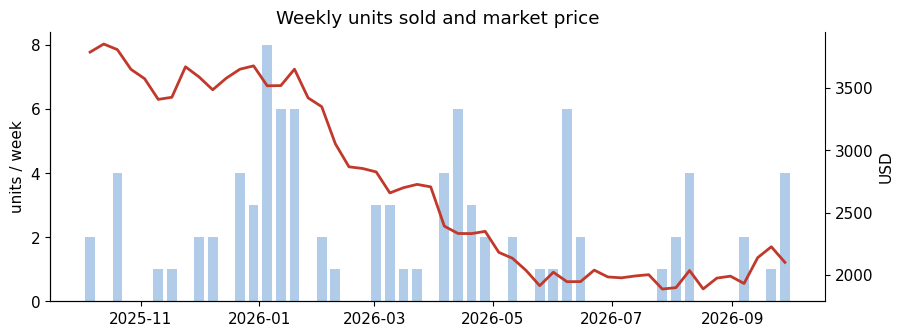

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(wk["date"], wk["qty"], width=5, color=BLUE, alpha=.35, label="units sold / week")
ax2 = ax.twinx(); ax2.plot(wk["date"], wk["market"], color=RED, lw=2, label="market price")
ax2.spines["right"].set_visible(True)
ax.set_ylabel("units / week"); ax2.set_ylabel("USD")
ax.set_title("Weekly units sold and market price")
plt.show()

## Step 2 · Demand: how many buyers arrive in *h* days?

**Concept — counting random arrivals.** If buyers arrived independently at a constant rate λ per day,
the number in *h* days would be **Poisson**($\lambda h$), whose variance equals its mean.
Real card sales are *clumpier*: a video, a tournament result or a restock brings bursts of buyers, then quiet weeks.
The **dispersion index**

$$\varphi = \frac{\operatorname{Var}(\text{weekly units})}{\operatorname{E}(\text{weekly units})}$$

measures this: $\varphi = 1$ is Poisson, $\varphi > 1$ is overdispersed.

The **Negative Binomial** is a Poisson whose rate is itself random (a Poisson–Gamma mixture).
We match its first two moments to the data (method of moments):

$$D_h \sim \text{NegBin}\big(\text{mean} = \lambda h,\ \text{variance} = \varphi\,\lambda h\big)$$

* λ uses the **last 13 weeks** (demand drifts; the recent level matters more);
* φ uses **all 52 weeks** (a dispersion estimate needs more data).

**Why it matters for risk.** We plan for a quiet window, not an average one. The model uses the **5th percentile**
$D_{h,\,0.05}$ as the "quiet market" number of buyers and the median as "normal". With the same mean, a larger φ
pushes the 5th percentile down — assuming Poisson would overstate liquidity exactly when it matters.

In [8]:
q = wk["qty"].to_numpy(float)

lam_manual = q[-13:].mean() / 7
phi_manual = max(1.0, q.var(ddof=1) / q.mean())
print(f"weekly mean (52w)      = {q.mean():.3f}")
print(f"weekly variance (52w)  = {q.var(ddof=1):.3f}")
print(f"phi = var / mean       = {phi_manual:.3f}")
print(f"lambda (last 13w) / 7  = {lam_manual:.4f} units/day")

demand = fit_demand(q.tolist())
assert math.isclose(demand.lam_day, lam_manual) and math.isclose(demand.phi, phi_manual)
print("\n✓ matches fit_demand():", demand)

weekly mean (52w)      = 1.750
weekly variance (52w)  = 4.113
phi = var / mean       = 2.350
lambda (last 13w) / 7  = 0.1538 units/day

✓ matches fit_demand(): Demand(lam_day=0.15384615384615383, phi=2.3501400560224086)


Quantiles by hand: map (mean $m$, dispersion φ) to scipy's NegBin parameters $n = m/(\varphi - 1)$, $p = 1/\varphi$,
which gives mean $m$ and variance $\varphi m$.

In [9]:
rows = []
for h in (7, 30, 60, 90):
    m = demand.lam_day * h
    if demand.phi > 1:
        n, p = m / (demand.phi - 1), 1 / demand.phi
        nb_med, nb_p05 = int(stats.nbinom.ppf(0.5, n, p)), int(stats.nbinom.ppf(0.05, n, p))
        assert nb_med == demand.quantile(h, 0.5) and nb_p05 == demand.quantile(h, 0.05)
    else:
        nb_med, nb_p05 = demand.quantile(h, 0.5), demand.quantile(h, 0.05)
    rows.append(dict(h_days=h, mean=round(m, 2), negbin_median=nb_med, negbin_p05=nb_p05,
                     poisson_p05=int(stats.poisson.ppf(0.05, m))))
pd.DataFrame(rows)

,h_days,mean,negbin_median,negbin_p05,poisson_p05
0,7,1.08,0,0,0
1,30,4.62,4,0,1
2,60,9.23,9,3,5
3,90,13.85,13,6,8


`negbin_p05` is never above `poisson_p05`: with φ > 1 the quiet-market case is worse, and a Poisson model would understate the risk.

## Step 3 · The ask ladder

**Concept — an order book with only one side.** A stock market's order book has bids and asks.
TCGplayer has only asks: a list of sellers, each with a price and a quantity. Buyers almost always take the
**cheapest landed price** (price + shipping), so listings sell in **price priority**: cheapest first.

We aggregate listings into price **levels** (same landed price → one step of the ladder).

**Data cleaning.** Real ladders contain junk asks (e.g. $6 for a $1,300 card — a mislabelled condition or product).
A genuine ask at 10% of market would be bought within minutes, so these are not competition we would have to beat.
`clean_ladder` drops asks below **60% of market**.

A one-number summary is **days of supply** = cards listed ÷ cards sold per day: how long the current listings would
take to sell if nobody listed anything new.

In [10]:
raw = load_listings(ITEM)
print("raw listings:", len(raw))
pd.DataFrame(raw).head(10)


raw listings: 30


,price,shipping,qty
0,1861.16,1.31,3
1,1922.92,1.31,1
2,1981.84,4.99,2
3,2066.66,1.31,1
4,2129.65,1.31,3
5,2134.33,1.31,1
6,2151.30,0.00,1
7,2167.33,0.00,1
8,2169.20,0.00,2
9,2170.33,0.00,1


In [11]:
ladder_raw = ladder_from_listings(raw)
ladder = clean_ladder(ladder_raw, MARKET, floor=0.60)

dropped = [l for l in ladder_raw if l not in ladder]
print(f"dropped {len(dropped)} levels below 60% of market (${0.6*MARKET:,.2f}):")
for l in dropped:
    print(f"  ${l.landed:>9,.2f} × {l.qty}")

lad_df = pd.DataFrame([(l.landed, l.qty) for l in ladder], columns=["landed", "qty"])
lad_df["cum_qty"] = lad_df["qty"].cumsum()
lad_df["vs_market"] = (lad_df["landed"] / MARKET - 1).map("{:+.1%}".format)
depth = int(lad_df["qty"].sum())
print(f"days of supply = {depth} cards / {demand.lam_day:.3f} per day = {depth / demand.lam_day:.0f} days")
lad_df.head(12)

dropped 0 levels below 60% of market ($1,260.00):
days of supply = 46 cards / 0.154 per day = 299 days


,landed,qty,cum_qty,vs_market
0,1862.47,3,3,-11.3%
1,1924.23,1,4,-8.4%
2,1986.83,2,6,-5.4%
3,2067.97,1,7,-1.5%
4,2130.96,3,10,+1.5%
5,2135.64,1,11,+1.7%
6,2151.30,1,12,+2.4%
7,2167.33,1,13,+3.2%
8,2169.20,2,15,+3.3%
9,2170.33,1,16,+3.3%


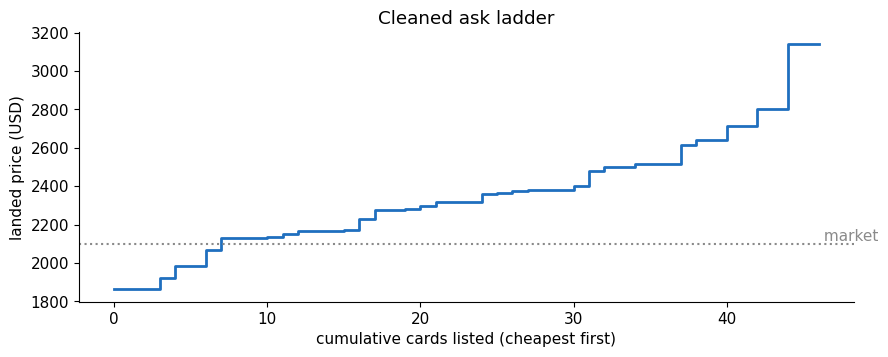

In [12]:
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.step(np.r_[0, lad_df["cum_qty"]], np.r_[lad_df["landed"].iloc[0], lad_df["landed"]], where="pre", color=BLUE, lw=2)
ax.axhline(MARKET, color=GRAY, ls=":"); ax.text(lad_df["cum_qty"].iloc[-1], MARKET, " market", va="bottom", color=GRAY)
ax.set_xlabel("cumulative cards listed (cheapest first)"); ax.set_ylabel("landed price (USD)")
ax.set_title("Cleaned ask ladder")
plt.show()

## Step 4 · Fees and net proceeds

**Concept — the fee floor.** Even selling exactly at market price costs money. As a TCGplayer seller:

$$\text{net}(p) = p\,(1 - 13.25\%) - \$0.30 - \text{shipping}(p)$$

(10.75% commission + 2.5% payment processing, $0.30 per order, and the seller's own shipping by value tier:
envelope → tracked → insured.)

The **haircut** of a sale is $1 - \text{cash received} / \text{market value}$.
$1 - \text{net(market)}/\text{market}$ is the **fee floor**: the smallest haircut possible, however long you wait.

In [13]:
for p in (10, 40, 100, MARKET):
    fee, ship = p * FEE_PCT, ship_cost(p)
    net = p - fee - FEE_FIXED - ship
    assert math.isclose(net, net_proceeds(p))
    print(f"sell at ${p:>9,.2f}: fee {fee:8.2f} + fixed {FEE_FIXED:.2f} + ship {ship:5.2f} → net ${net:>9,.2f}  haircut {1-net/p:6.2%}")

sell at $    10.00: fee     1.33 + fixed 0.30 + ship  0.75 → net $     7.62  haircut 23.75%
sell at $    40.00: fee     5.30 + fixed 0.30 + ship  1.50 → net $    32.90  haircut 17.75%
sell at $   100.00: fee    13.25 + fixed 0.30 + ship  5.50 → net $    80.95  haircut 19.05%
sell at $ 2,100.00: fee   278.25 + fixed 0.30 + ship 12.00 → net $ 1,809.45  haircut 13.84%


The last line is this card's **fee floor**.

## Step 5 · Selling into the ask ladder

**Concept — price priority.** Suppose $D$ buyers arrive within the window and each buys the cheapest card available.
To sell **q** cards, at most

$$\text{room} = D - q$$

cards may be priced below ours (they are bought first, then ours). So we walk up the ladder, let levels stay below us
while they fit inside `room`, and **undercut by one cent** the first level that would not fit.
We never assume a sale *above* market price.

**Two escape hatches:**

1. If $D < q$ there are too few buyers. We undercut the cheapest ask, sell $D$ cards, and send the other $q - D$
   to the **outside option**.
2. The outside option is a **shop / buylist bid** at `dump_frac` × market (60% by default; an assumption, see the Summary).
   If undercutting would net less than the shop pays, everything goes to the shop.

With $D = D_{h,\alpha}$ from step 2 this gives the cash raised **with confidence 1 − α**.
The function below does exactly what `liquidate()` does but prints every decision.

In [14]:
def liquidate_verbose(ladder, market, q, demand, h, alpha, dump_frac=0.60):
    D = demand.quantile(h, alpha)
    print(f"h = {h} days, alpha = {alpha}: D = {D} buyers, holding q = {q}")
    bid = dump_frac * market
    if D < q:
        price = min(market, ladder[0].landed - TICK)
        sold, dumped = D, q - D
        print(f"  D < q → undercut the cheapest ask at ${price:,.2f}, sell {sold}, send {dumped} to the shop at ${bid:,.2f}")
    else:
        room, below, price = D - q, 0, market
        print(f"  room = D − q = {room}")
        for lvl in ladder:
            if below + lvl.qty > room:
                price = min(market, lvl.landed - TICK)
                cap = f", above market so capped at ${market:,.2f}" if lvl.landed - TICK > market else ""
                print(f"  level ${lvl.landed:,.2f} ×{lvl.qty}: cumulative {below + lvl.qty} > {room} → undercut at ${lvl.landed - TICK:,.2f}{cap}")
                break
            below += lvl.qty
            print(f"  level ${lvl.landed:,.2f} ×{lvl.qty}: cumulative {below} ≤ {room} → may stay below us")
        else:
            print(f"  room covers the whole ladder → list at market ${price:,.2f}")
        sold, dumped = q, 0
    if net_proceeds(price) < bid:
        print(f"  net ${net_proceeds(price):,.2f} < shop bid ${bid:,.2f} → sell everything to the shop")
        sold, dumped = 0, q
    proceeds = sold * net_proceeds(price) + dumped * bid
    print(f"  → cash ${proceeds:,.2f}  haircut {1 - proceeds / (q * market):.2%}")
    return proceeds

for h, a in [(3, 0.5), (7, 0.5), (30, 0.5), (30, 0.05), (90, 0.05)]:
    mine = liquidate_verbose(ladder, MARKET, QTY, demand, h, a)
    assert math.isclose(mine, liquidate(ladder, MARKET, QTY, demand, h, a).proceeds)
    print()
print("✓ every case matches liquidate()")

h = 3 days, alpha = 0.5: D = 0 buyers, holding q = 1
  D < q → undercut the cheapest ask at $1,862.46, sell 0, send 1 to the shop at $1,260.00
  → cash $1,260.00  haircut 40.00%

h = 7 days, alpha = 0.5: D = 0 buyers, holding q = 1
  D < q → undercut the cheapest ask at $1,862.46, sell 0, send 1 to the shop at $1,260.00
  → cash $1,260.00  haircut 40.00%

h = 30 days, alpha = 0.5: D = 4 buyers, holding q = 1
  room = D − q = 3
  level $1,862.47 ×3: cumulative 3 ≤ 3 → may stay below us
  level $1,924.23 ×1: cumulative 4 > 3 → undercut at $1,924.22
  → cash $1,656.96  haircut 21.10%

h = 30 days, alpha = 0.05: D = 0 buyers, holding q = 1
  D < q → undercut the cheapest ask at $1,862.46, sell 0, send 1 to the shop at $1,260.00
  → cash $1,260.00  haircut 40.00%

h = 90 days, alpha = 0.05: D = 6 buyers, holding q = 1
  room = D − q = 5
  level $1,862.47 ×3: cumulative 3 ≤ 5 → may stay below us
  level $1,924.23 ×1: cumulative 4 ≤ 5 → may stay below us
  level $1,986.83 ×2: cumulative 6 > 5

Try `QTY = 3` or `5` and re-run: `room` shrinks, you must undercut deeper, and the haircut rises. That size dependence is **endogenous** liquidity risk.

## Step 6 · The price–time frontier

**Concept.** Repeat step 5 for every horizon from 1 to 120 days. The more time you allow, the more buyers arrive,
the more listings can stay below you, and the closer you get to the fee floor. Selling *today* means the shop bid.

Drawn for normal demand (median) and a quiet market (5th percentile), with **days to liquidate**:
the shortest horizon at which the quiet-market haircut is ≤ 20%.

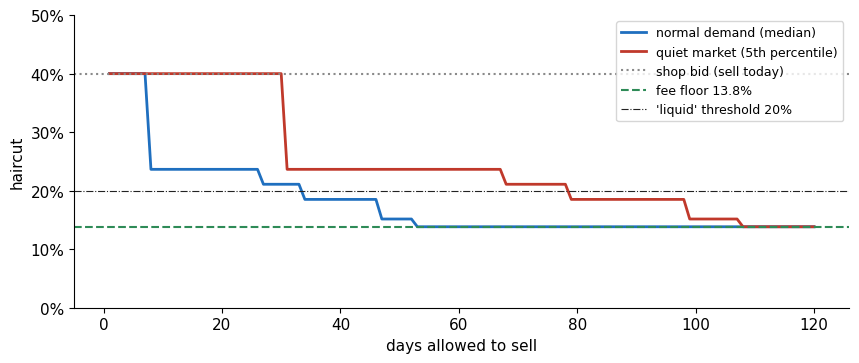

days to liquidate (quiet market, haircut ≤ 20%): 80 days


In [15]:
hs = np.arange(1, 121)
med = [liquidate(ladder, MARKET, QTY, demand, h, 0.50).haircut for h in hs]
quiet = [liquidate(ladder, MARKET, QTY, demand, h, 0.05).haircut for h in hs]
floor = 1 - net_proceeds(MARKET) / MARKET

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(hs, med, color=BLUE, lw=2, label="normal demand (median)")
ax.plot(hs, quiet, color=RED, lw=2, label="quiet market (5th percentile)")
ax.axhline(1 - DUMP_FRAC, color=GRAY, ls=":", label="shop bid (sell today)")
ax.axhline(floor, color=GREEN, ls="--", label=f"fee floor {floor:.1%}")
ax.axhline(MAX_HAIRCUT, color=DARK, ls="-.", lw=0.8, label="'liquid' threshold 20%")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_ylim(0, 0.5); ax.set_xlabel("days allowed to sell"); ax.set_ylabel("haircut"); ax.legend(fontsize=9)
plt.show()

print(f"days to liquidate (quiet market, haircut ≤ 20%): {days_to_liquidate(ladder, MARKET, QTY, demand, MAX_HAIRCUT)} days")

## Step 7 · Price risk: the market may fall while you wait

**Concept — Value at Risk.** VaR at 95% is the loss exceeded only 5% of the time over a horizon.
With weekly log returns $r_t = \ln(P_t / P_{t-1})$, mean μ and standard deviation σ:

$$\text{loss}_{H} = -\big(\mu_H + z_{\alpha}\,\sigma\sqrt{H}\big), \qquad \text{VaR}_H = 1 - e^{-\text{loss}_H}$$

* **Time scaling.** Log returns add over time. If weeks are independent, variances add, so the standard deviation
  over $H$ weeks is $\sigma\sqrt{H}$ while the drift is $H\mu$.
* **Drift.** Following Bangia et al. (who set $E[r]=0$), a **positive drift is not credited**: $\mu_H = H\cdot\min(\mu, 0)$.
  A hype-driven uptrend would otherwise shrink the risk number exactly when it is least trustworthy.

**Concept — Cornish–Fisher.** Card returns are skewed and fat-tailed, not normal. The Cornish–Fisher expansion adjusts
the normal quantile $z$ using skewness $s$ and excess kurtosis $k$:

$$z_{cf} = z + \frac{(z^2-1)s}{6} + \frac{(z^3-3z)k}{24} - \frac{(2z^3-5z)s^2}{36}$$

(Weekly $s, k$ are used as-is for 4 weeks; under independence they would shrink, so this is the conservative choice.)

**Validity domain.** The expansion only makes sense while $z \mapsto z_{cf}$ is increasing. Very thinly traded cards
(most weeks have no sale, so the return is 0, plus one big jump) produce extreme $s, k$ that fold the map over and can
even give a negative loss. `cf_valid` checks monotonicity on $z \in [-4, 4]$; outside the valid domain the model uses
the standardized empirical quantile instead, never milder than the normal $z$, and floors the loss at 0.
Holdings with fewer than 13 weeks containing a sale are flagged as unreliable in step 9.

In [16]:
r = wk["ret"].dropna().to_numpy()
mu, sig, sk, ku = r.mean(), r.std(ddof=1), stats.skew(r), stats.kurtosis(r)
print(f"{len(r)} weeks · mean = {mu:+.4f} · sigma = {sig:.4f} · skew = {sk:.3f} · excess kurtosis = {ku:.3f}")
print(f"empirical 5th percentile = {np.quantile(r, 0.05):.4f}")

z = stats.norm.ppf(0.05)                       # −1.645
H = 4
if cf_valid(sk, ku):
    zq = z + (z**2 - 1)*sk/6 + (z**3 - 3*z)*ku/24 - (2*z**3 - 5*z)*sk**2/36
    print(f"Cornish–Fisher map is valid: z normal = {z:.3f} → z_cf = {zq:.3f}")
else:
    zq = min(z, (np.quantile(r, 0.05) - mu) / sig)
    print(f"Cornish–Fisher map is NOT valid for these moments → empirical z = {zq:.3f}")

loss1 = max(0.0, -(min(mu, 0) + zq * sig))
loss4 = max(0.0, -(min(mu, 0) * H + zq * sig * math.sqrt(H)))
assert math.isclose(loss1, cornish_fisher_var(r, 0.95)) and math.isclose(loss4, cornish_fisher_var(r, 0.95, H))
var4w = 1 - math.exp(-loss4)
print(f"1-week loss quantile = {loss1:.4f} (log) · 4-week = {loss4:.4f} (log) → VaR 95% 4w = {var4w:.2%}")
print(f"(plain normal, zero drift: 1.645 × sigma × 2 = {1.645*sig*2:.2%})")

51 weeks · mean = -0.0116 · sigma = 0.0443 · skew = 0.053 · excess kurtosis = 0.116
empirical 5th percentile = -0.0749
Cornish–Fisher map is valid: z normal = -1.645 → z_cf = -1.627
1-week loss quantile = 0.0837 (log) · 4-week = 0.1906 (log) → VaR 95% 4w = 17.35%
(plain normal, zero drift: 1.645 × sigma × 2 = 14.59%)


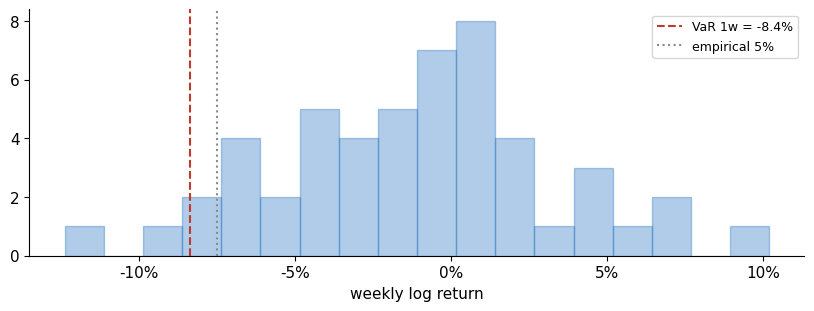

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(r, bins=18, color=BLUE, alpha=.35, edgecolor=BLUE)
ax.axvline(-loss1, color=RED, ls="--", label=f"VaR 1w = {-loss1:.1%}")
ax.axvline(np.quantile(r, 0.05), color=GRAY, ls=":", label="empirical 5%")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("weekly log return"); ax.legend(fontsize=9)
plt.show()

## Step 8 · Bangia LVaR, Amihud and the combined loss

**Concept — liquidity-adjusted VaR (Bangia, Diebold, Schuermann & Stroughair 1999).** Ordinary VaR values a position
at the **mid** price. A seller receives the **bid**, on average half a spread lower: $\text{bid} = P(1 - S/2)$ with
relative spread $S = (\text{ask} - \text{bid})/\text{mid}$. Spreads widen in bad markets, so take a bad spread too:

$$P' = P\,e^{r_{\alpha}}\,\big(1 - \tfrac12(\mu_S + a\,\sigma_S)\big)$$

Expanding $1 - P'/P$ and dropping the small cross term (which makes the number slightly larger, i.e. conservative):

$$\frac{\text{LVaR}}{P} \approx \underbrace{1 - e^{r_\alpha}}_{\text{price VaR (step 7)}} \;+\; \underbrace{\tfrac12\,(\mu_S + a\,\sigma_S)}_{\text{cost of liquidity}}$$

Three modelling choices:

1. **Spread proxy.** TCGplayer has no bid, so there is no quoted spread. The model uses the weekly sale-price range
   $S = (\text{high} - \text{low})/\text{market}$; half of it is the distance from the middle of the week's fills down to the
   lowest fill — what an impatient seller gets.
2. **Scaling factor $a$.** Spread distributions are far from normal; Bangia et al. find $a \approx 2.0$–$4.5$.
   The model reads $a$ off the data: $a = (\text{95th percentile of } S - \mu_S)/\sigma_S$, floored at the normal 1.645.
3. **No time scaling** for the spread term: it is a one-off exit cost.

Adding the two terms assumes the worst price and the worst spread happen together (the paper's assumption; in crashes they do).

**Concept — Amihud illiquidity.** Average of $|r_t| / \text{dollar volume}_t$ (here per $1,000 traded):
how much the price moves per dollar of trading. Higher = less liquid.

**Concept — combined loss.** Bangia's measure does not depend on how many cards you hold (*exogenous*).
The headline number combines price VaR with the size-dependent (*endogenous*) haircut of step 5:

$$\text{combined}_{30d} = 1 - (1 - \text{VaR}_{4w})\,(1 - \text{haircut}_{30d,\ \alpha=5\%})$$

Losses compound multiplicatively: the haircut is paid on a price that has already fallen.

In [18]:
S = wk["spread"].dropna().to_numpy()
mu_s, sd_s = S.mean(), S.std(ddof=1)
a_hand = max(stats.norm.ppf(0.95), (np.quantile(S, 0.95) - mu_s) / sd_s) if len(S) >= 20 else stats.norm.ppf(0.95)
addon = 0.5 * (mu_s + a_hand * sd_s)

b = bangia_lvar(wk["ret"].to_numpy(), wk["spread"].to_numpy(), 0.95, 4)
assert math.isclose(a_hand, b.a) and math.isclose(addon, b.liq_addon) and math.isclose(var4w, b.price_var)
print(f"spread proxy: mean {mu_s:.2%}, sd {sd_s:.2%} over {len(S)} weeks, 95th pct {np.quantile(S, 0.95):.2%}")
print(f"scaling factor a = {a_hand:.2f} (normal would be 1.645)")
print(f"cost of liquidity = ½({mu_s:.4f} + {a_hand:.2f}×{sd_s:.4f}) = {addon:.2%}")
print(f"Bangia LVaR = {var4w:.2%} + {addon:.2%} = {b.lvar:.2%}")

m = (wk["dvol"] > 0) & wk["ret"].notna()
ami = (wk.loc[m, "ret"].abs() / wk.loc[m, "dvol"]).mean() * 1e3
assert math.isclose(ami, amihud(wk["ret"].to_numpy(), wk["dvol"].to_numpy()))
print(f"Amihud = {ami:.4f} (|return| per $1,000 traded)")

hc30 = liquidate(ladder, MARKET, QTY, demand, 30, 0.05).haircut
print(f"\ncombined 30d = 1 − (1 − {var4w:.4f})(1 − {hc30:.4f}) = {1 - (1 - var4w) * (1 - hc30):.2%}")

spread proxy: mean 8.89%, sd 5.17% over 23 weeks, 95th pct 15.49%
scaling factor a = 1.64 (normal would be 1.645)
cost of liquidity = ½(0.0889 + 1.64×0.0517) = 8.70%
Bangia LVaR = 17.35% + 8.70% = 26.05%
Amihud = 0.0077 (|return| per $1,000 traded)

combined 30d = 1 − (1 − 0.1735)(1 − 0.4000) = 50.41%


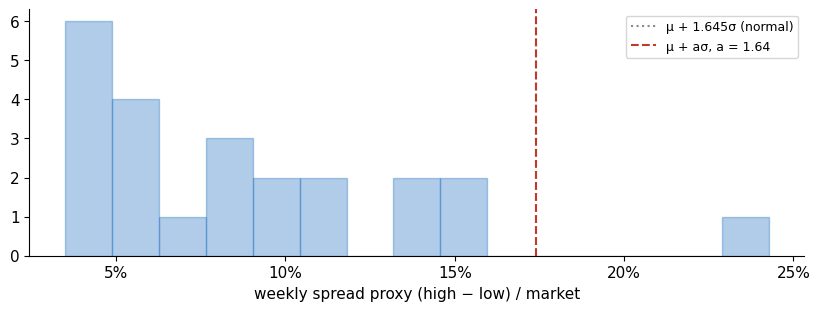

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.hist(S, bins=15, color=BLUE, alpha=.35, edgecolor=BLUE)
ax.axvline(mu_s + 1.645 * sd_s, color=GRAY, ls=":", label="μ + 1.645σ (normal)")
ax.axvline(mu_s + b.a * sd_s, color=RED, ls="--", label=f"μ + aσ, a = {b.a:.2f}")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("weekly spread proxy (high − low) / market"); ax.legend(fontsize=9)
plt.show()

## Step 9 · The whole portfolio + stress tests

**Concept — diversification.** Portfolio VaR is not the weighted sum of single-card VaRs: cards do not all fall in the
same week. The portfolio's weekly return is built from value weights, $r_p = \ln\big(1 + \sum_i w_i (e^{r_i} - 1)\big)$,
and step 7 is applied to it.

**Concept — stress testing.** VaR describes ordinary bad weeks inside the sample. A stress test asks "what if" about an
event the sample may not contain. Two hypothetical scenarios (not calibrated to a specific episode):

* `demand_crunch` — the hype unwinds: buyers fall to 40%, prices to 75%, and holders rush to list (listings ×1.5);
* `reprint` — a supply shock on reprint-exposed items only: buyers ×0.7, price ×0.65, listings ×3.

**Your own portfolio:** build a dataset folder with the same layout and edit `portfolio.json` (id, name, qty, `reprint_risk` for items still in print, optional `dump_frac`).

In [20]:
HOLDINGS = portfolio["positions"]
pd.DataFrame(HOLDINGS)


,id,name,qty,reprint_risk
0,card_a,Card A · chase single,1,False
1,card_b,Card B · alt-art single,1,False
2,card_c,Card C · new-set chase card,2,True
3,card_d,Card D · mid-value single,3,True
4,box_e,Box E · sealed booster box,1,False
5,box_f,Box F · premium collection,2,False
6,box_g,Box G · exclusive box,4,False


In [21]:
def analyse_position(pos):
    """Steps 1–8 for one holding."""
    iid, q, game = str(pos["id"]), int(pos.get("qty", 1)), pos.get("game", "")

    wk = load_weekly(iid)
    raw = ladder_from_listings(load_listings(iid))
    market = float(wk["market"].iloc[-1]) if len(wk) and not math.isnan(wk["market"].iloc[-1]) \
        else float(pos.get("market_override", float("nan")))
    ladder = clean_ladder(raw, market) if market > 0 else raw
    demand = fit_demand(wk["qty"].tolist()) if len(wk) else Demand(0.0, 1.0)
    dump = float(pos.get("dump_frac", DUMP_FRAC))
    depth = sum(l.qty for l in ladder)
    pr = PositionRisk(
        name=pos.get("name") or iid, qty=q, market=market, value=q * market,
        lam_day=demand.lam_day, phi=demand.phi, book_depth=depth,
        days_of_supply=depth / demand.lam_day if demand.lam_day > 0 else float("inf"),
        best_ask=ladder[0].landed if ladder else float("nan"),
        dump_frac=dump, bid_source="position" if "dump_frac" in pos else "assumed", game=game,
        trade_weeks=int((wk["txn"] > 0).sum()) if len(wk) else 0,
    )
    if not (market > 0):
        return pr, wk, ladder
    for h in HORIZONS:
        for a in ALPHAS:
            pr.liq[(h, a)] = liquidate(ladder, market, q, demand, h, a, dump)
    pr.days_to_liq = days_to_liquidate(ladder, market, q, demand, MAX_HAIRCUT, dump_frac=dump)
    pr.bangia = bangia_lvar(wk["ret"].to_numpy(), wk["spread"].to_numpy(), 0.95, 4)
    pr.amihud = amihud(wk["ret"].to_numpy(), wk["dvol"].to_numpy())
    hc30 = pr.liq[(30, 0.05)].haircut
    if not math.isnan(pr.bangia.price_var):
        pr.combined_30d = 1 - (1 - pr.bangia.price_var) * (1 - hc30)
    return pr, wk, ladder


def run_portfolio(holdings):
    """Every holding → portfolio MTM, liquidation values, diversified VaR, combined loss, stress."""
    pos, weekly, ladders, inputs = [], {}, {}, []
    for p in holdings:
        pr, wk, lad = analyse_position(p)
        if pr.market > 0:
            pos.append(pr); weekly[pr.name], ladders[pr.name] = wk, lad; inputs.append(p)
    mtm = sum(p.value for p in pos)
    liq_value = {k: sum(p.liq[k].proceeds for p in pos) for k in pos[0].liq}

    rets = pd.concat({p.name: weekly[p.name].set_index("date")["ret"] for p in pos}, axis=1).dropna()
    w = np.array([p.value / mtm for p in pos])
    port = np.log1p((np.expm1(rets.to_numpy()) * w).sum(axis=1))      # value-weighted weekly return
    pvar = 1 - math.exp(-cornish_fisher_var(port, 0.95, horizon=4)) if len(rets) >= 8 else float("nan")
    hc30 = 1 - liq_value[(30, 0.05)] / mtm
    combined = 1 - (1 - pvar) * (1 - hc30) if not math.isnan(pvar) else float("nan")

    stress = {}
    for name, s in SCENARIOS.items():
        total = 0.0
        for p, inp in zip(pos, inputs):
            if s["only_flagged"] and not inp.get("reprint_risk", False):
                total += p.liq[(30, 0.05)].proceeds
                continue
            d = Demand(p.lam_day * s["lam"], p.phi)
            lad = scale_ladder(ladders[p.name], s["price"], s["depth"])
            total += liquidate(lad, p.market * s["price"], p.qty, d, 30, 0.05, p.dump_frac).proceeds
        stress[name] = {"value": total, "loss": 1 - total / mtm}
    return dict(positions=pos, mtm=mtm, liq_value=liq_value, price_var_4w=pvar, combined_30d=combined,
                stress=stress, weekly=weekly, ladders=ladders)

In [22]:
R = run_portfolio(HOLDINGS)

tbl = pd.DataFrame([dict(
    holding=p.name, qty=p.qty, market=p.market, best_ask=p.best_ask,
    lam_day=round(p.lam_day, 2), phi=round(p.phi, 2), trade_weeks=p.trade_weeks, days_of_supply=round(p.days_of_supply),
    hc30_normal=p.liq[(30, 0.5)].haircut, hc30_quiet=p.liq[(30, 0.05)].haircut,
    days_to_liq=p.days_to_liq, price_var_4w=p.bangia.price_var, a=p.bangia.a, bangia_lvar=p.bangia.lvar,
    reliable_var=p.trade_weeks >= MIN_TRADE_WEEKS,
) for p in R["positions"]])
tbl.style.format({"market": "${:,.0f}", "best_ask": "${:,.0f}", "hc30_normal": "{:.1%}", "hc30_quiet": "{:.1%}",
                  "price_var_4w": "{:.1%}", "a": "{:.2f}", "bangia_lvar": "{:.1%}"})

,holding,qty,market,best_ask,lam_day,phi,trade_weeks,days_of_supply,hc30_normal,hc30_quiet,days_to_liq,price_var_4w,a,bangia_lvar,reliable_var
0,Card A · chase single,1,"$2,100","$1,862",0.150000,2.350000,32,299,21.1%,40.0%,80,17.4%,1.64,26.0%,True
1,Card B · alt-art single,1,"$1,300","$1,095",0.100000,1.020000,29,303,27.4%,40.0%,110,18.2%,1.64,26.3%,True
2,Card C · new-set chase card,2,"$1,500","$1,328",0.460000,1.370000,50,165,14.1%,18.2%,19,25.4%,2.00,46.2%,True
3,Card D · mid-value single,3,$500,$492,0.670000,4.620000,46,121,15.7%,15.7%,18,23.3%,1.80,36.3%,True
4,Box E · sealed booster box,1,"$2,200","$2,003",0.790000,6.030000,38,252,13.8%,13.8%,15,11.2%,1.91,19.8%,True
5,Box F · premium collection,2,$850,$817,1.080000,9.200000,44,202,14.7%,14.7%,14,11.7%,1.73,20.4%,True
6,Box G · exclusive box,4,"$1,200",$989,0.160000,1.580000,31,631,28.9%,37.4%,110,15.3%,1.64,25.5%,True


In [23]:
w = np.array([p.value / R["mtm"] for p in R["positions"]])
print("weights:", {p.name: f"{wi:.1%}" for p, wi in zip(R["positions"], w)})
print(f"\nportfolio VaR 4w = {R['price_var_4w']:.2%}  (value-weighted average of single-card VaRs = {(tbl['price_var_4w'] * w).sum():.2%})")
print("lower because of diversification: the cards do not all move together")

summary = {
    "mark-to-market": R["mtm"],
    "30d, normal demand": R["liq_value"][(30, 0.5)],
    "30d, quiet market": R["liq_value"][(30, 0.05)],
    "sell everything today": R["liq_value"][(1, 0.05)],
    **{f"stress: {k}": v["value"] for k, v in R["stress"].items()},
}
s = pd.Series(summary)
print(f"\ncombined 30d loss (portfolio) = {R['combined_30d']:.2%}")
pd.DataFrame({"USD": s.map("${:,.0f}".format), "loss vs MTM": (1 - s / R["mtm"]).map("{:.1%}".format)})

weights: {'Card A · chase single': '12.7%', 'Card B · alt-art single': '7.8%', 'Card C · new-set chase card': '18.1%', 'Card D · mid-value single': '9.0%', 'Box E · sealed booster box': '13.3%', 'Box F · premium collection': '10.2%', 'Box G · exclusive box': '28.9%'}

portfolio VaR 4w = 8.23%  (value-weighted average of single-card VaRs = 17.43%)
lower because of diversification: the cards do not all move together

combined 30d loss (portfolio) = 33.05%


,USD,loss vs MTM
mark-to-market,"$16,600",0.0%
"30d, normal demand","$13,203",20.5%
"30d, quiet market","$12,109",27.1%
sell everything today,"$9,960",40.0%
stress: demand_crunch,"$8,344",49.7%
stress: reprint,"$10,660",35.8%


**Where the 30-day gap comes from** — the headline number split into its three parts:
fees (paid even at market price), the cost of pricing below other listings, and price risk while waiting.

In [24]:
fees = sum(p.qty * (p.market - net_proceeds(p.market)) for p in R["positions"])
liq = R["liq_value"][(30, 0.05)]
steps = {"mark-to-market": R["mtm"], "fees + shipping": -fees, "pricing below others": -(R["mtm"] - fees - liq),
         "price risk (VaR 95%)": -liq * R["price_var_4w"]}
final = liq * (1 - R["price_var_4w"])
assert math.isclose(final, R["mtm"] * (1 - R["combined_30d"]))
for k, v in steps.items():
    print(f"{k:>24}: {'+' if v > 0 else '−'}${abs(v):>9,.0f}")
print(f"{'cash you can count on':>24}:  ${final:>9,.0f}  ({1 - final / R['mtm']:.1%} below mark-to-market)")

          mark-to-market: +$   16,600
         fees + shipping: −$    2,372
    pricing below others: −$    2,119
    price risk (VaR 95%): −$      996
   cash you can count on:  $   11,113  (33.1% below mark-to-market)


## Step 10 · Sensitivity: which assumption matters most?

Change the grid and re-run:

* `qty` — holding more copies means undercutting deeper (endogenous liquidity);
* `dump_frac` — the shop bid; it caps the haircut at $1 - \text{dump\_frac}$;
* `demand_mult` — demand disappearing.

In [25]:
rows = []
for qty in (1, 2, 3, 5):
    for dump_frac in (0.5, 0.6, 0.7):
        for demand_mult in (1.0, 0.5):
            d = Demand(demand.lam_day * demand_mult, demand.phi)
            Lq = liquidate(ladder, MARKET, qty, d, 30, 0.05, dump_frac)
            rows.append(dict(qty=qty, dump_frac=dump_frac, demand_mult=demand_mult, D_30d_p05=Lq.demand,
                             price=Lq.price, sold=Lq.sold_market, to_shop=Lq.dumped, haircut=f"{Lq.haircut:.1%}"))
pd.DataFrame(rows)

,qty,dump_frac,demand_mult,D_30d_p05,price,sold,to_shop,haircut
0,1,0.5,1.0,0,1862.46,0,1,50.0%
1,1,0.5,0.5,0,1862.46,0,1,50.0%
2,1,0.6,1.0,0,1862.46,0,1,40.0%
3,1,0.6,0.5,0,1862.46,0,1,40.0%
4,1,0.7,1.0,0,1862.46,0,1,30.0%
5,1,0.7,0.5,0,1862.46,0,1,30.0%
6,2,0.5,1.0,0,1862.46,0,2,50.0%
7,2,0.5,0.5,0,1862.46,0,2,50.0%
8,2,0.6,1.0,0,1862.46,0,2,40.0%
9,2,0.6,0.5,0,1862.46,0,2,40.0%


## Summary

| # | Concept | Formula / rule | What it tells you |
|---|---|---|---|
| 1 | Overdispersed demand | $D_h \sim \text{NegBin}(\lambda h,\ \varphi\lambda h)$ | how many buyers a quiet window brings |
| 2 | Ask ladder, price priority | undercut the first level that does not fit in $D - q$ | the price needed to sell in time |
| 3 | Outside option | shop bid = `dump_frac` × market | the floor under every outcome |
| 4 | Fee floor | $1 - \text{net(market)}/\text{market}$ | minimum haircut even at market |
| 5 | Price–time frontier | haircut($h$), $h = 1 \dots 120$ | patience is worth money |
| 6 | Price VaR | $1 - e^{-(H\min(\mu,0) + z_{cf}\sigma\sqrt H)}$ | how far the price may fall while waiting |
| 7 | Bangia LVaR | price VaR + $\tfrac12(\mu_S + a\sigma_S)$ | exogenous cost of liquidity |
| 8 | Combined loss | $1 - (1-\text{VaR})(1-\text{haircut})$ | the headline 30-day number |
| 9 | Stress tests | demand ×, price ×, listings × | what VaR cannot see |

**Known limitations** (all conservative except the first): the listings are held fixed over the horizon (no new
competing listings), only one marketplace's demand counts (no other channels), proceeds are capped at market price, and the
stress scenarios are hypothetical.

**References.** Bangia, Diebold, Schuermann & Stroughair (1999), *Modeling Liquidity Risk, with Implications for
Traditional Market Risk Measurement and Management*. Amihud (2002), *Illiquidity and Stock Returns*, Journal of Financial
Markets 5(1). Cornish & Fisher (1938), *Moments and Cumulants in the Specification of Distributions*.

**About the 60% shop bid.** It is an assumption. In the full project it was cross-checked against real standing bids on tokenized graded cards; that step needs a live API and is not part of this offline version.
